In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


All libraries imported successfully!
Pandas version: 3.0.6
NumPy version: 2.5.4


In [2]:

import os

print("Current folder:", os.getcwd())
print("Files in data folder:", os.listdir("../data"))


Current folder: C:\Users\ANKIT TRIPATHI\Supply-Chain-Inventory-Analysis\notebooks
Files in data folder: ['.ipynb_checkpoints', 'Project-03 supply_chain_inventory_dataset_15000_rows 2.xlsx']


In [4]:

import pandas as pd

df = pd.read_excel("../data/Project-03 supply_chain_inventory_dataset_15000_rows 2.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (15000, 13)


,Product_ID,Product_Name,Category,Supplier_Name,Order_Date,Delivery_Date,Stock_Quantity,Reorder_Level,Units_Sold,Purchase_Cost,Selling_Price,Warehouse_Location,Shipping_Time_Days
0,PROD1000,Tablet,Fashion,Supplier D,2023-08-02,2023-08-07,3,59,241,1800,2081,Chennai,5
1,PROD1001,Tablet,Fashion,Supplier D,2024-04-11,2024-04-13,118,105,70,1950,2169,Hyderabad,2
2,PROD1002,Mixer,Sports,Supplier A,2024-08-16,2024-08-20,57,108,107,828,1322,Bangalore,4
3,PROD1003,TV,Sports,Supplier B,2024-11-30,2024-12-02,420,129,271,317,598,Chennai,2
4,PROD1004,Mixer,Fashion,Supplier C,2024-08-03,2024-08-11,401,77,210,645,1061,Mumbai,8


In [5]:

print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()


Column names:
['Product_ID', 'Product_Name', 'Category', 'Supplier_Name', 'Order_Date', 'Delivery_Date', 'Stock_Quantity', 'Reorder_Level', 'Units_Sold', 'Purchase_Cost', 'Selling_Price', 'Warehouse_Location', 'Shipping_Time_Days']

Data types:
Product_ID                       str
Product_Name                     str
Category                         str
Supplier_Name                    str
Order_Date            datetime64[us]
Delivery_Date         datetime64[us]
Stock_Quantity                 int64
Reorder_Level                  int64
Units_Sold                     int64
Purchase_Cost                  int64
Selling_Price                  int64
Warehouse_Location               str
Shipping_Time_Days             int64
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Product_ID          150

In [6]:

# 1. Total rows and columns
print("Dataset shape:", df.shape)

# 2. Missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# 3. Total duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 4. Summary of numerical columns
print("\nNumerical summary:")
display(df.describe())


Dataset shape: (15000, 13)

Missing values:
Product_ID            0
Product_Name          0
Category              0
Supplier_Name         0
Order_Date            0
Delivery_Date         0
Stock_Quantity        0
Reorder_Level         0
Units_Sold            0
Purchase_Cost         0
Selling_Price         0
Warehouse_Location    0
Shipping_Time_Days    0
dtype: int64

Duplicate rows: 0

Numerical summary:


,Order_Date,Delivery_Date,Stock_Quantity,Reorder_Level,Units_Sold,Purchase_Cost,Selling_Price,Shipping_Time_Days
count,15000,15000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,2023-12-28 15:20:09.600000,2024-01-03 03:14:35.520000,250.917933,99.802467,148.167200,1102.676733,1378.474133,5.496133
min,2023-01-01 00:00:00,2023-01-02 00:00:00,0.000000,50.000000,0.000000,200.000000,263.000000,1.000000
25%,2023-06-26 00:00:00,2023-07-02 00:00:00,126.000000,74.000000,72.000000,641.000000,918.000000,3.000000
50%,2023-12-26 00:00:00,2023-12-31 00:00:00,251.000000,100.000000,146.000000,1102.000000,1374.000000,6.000000
75%,2024-07-01 00:00:00,2024-07-07 00:00:00,375.000000,126.000000,224.000000,1560.000000,1836.000000,8.000000
max,2024-12-31 00:00:00,2025-01-10 00:00:00,500.000000,150.000000,300.000000,2000.000000,2492.000000,10.000000
std,NaN,NaN,144.554751,29.406247,86.652443,525.703573,541.562695,2.885690


In [7]:

print(df.dtypes)


Product_ID                       str
Product_Name                     str
Category                         str
Supplier_Name                    str
Order_Date            datetime64[us]
Delivery_Date         datetime64[us]
Stock_Quantity                 int64
Reorder_Level                  int64
Units_Sold                     int64
Purchase_Cost                  int64
Selling_Price                  int64
Warehouse_Location               str
Shipping_Time_Days             int64
dtype: object


In [8]:

print("Date columns:")
print("Order_Date:", df["Order_Date"].dtype)
print("Delivery_Date:", df["Delivery_Date"].dtype)

print("\nNumeric columns:")
numeric_columns = [
    "Stock_Quantity",
    "Reorder_Level",
    "Units_Sold",
    "Purchase_Cost",
    "Selling_Price",
    "Shipping_Time_Days"
]

print(df[numeric_columns].dtypes)


Date columns:
Order_Date: datetime64[us]
Delivery_Date: datetime64[us]

Numeric columns:
Stock_Quantity        int64
Reorder_Level         int64
Units_Sold            int64
Purchase_Cost         int64
Selling_Price         int64
Shipping_Time_Days    int64
dtype: object


In [9]:

# Check for negative values in important numeric columns
numeric_columns = [
    "Stock_Quantity",
    "Reorder_Level",
    "Units_Sold",
    "Purchase_Cost",
    "Selling_Price",
    "Shipping_Time_Days"
]

print("Negative values in each column:")
for col in numeric_columns:
    print(f"{col}: {(df[col] < 0).sum()}")

# Check whether delivery date is earlier than order date
print("\nDelivery before order:",
      (df["Delivery_Date"] < df["Order_Date"]).sum())

# Check whether shipping days match the date difference
date_difference = (
    df["Delivery_Date"] - df["Order_Date"]
).dt.days

print("Shipping time mismatches:",
      (date_difference != df["Shipping_Time_Days"]).sum())


Negative values in each column:
Stock_Quantity: 0
Reorder_Level: 0
Units_Sold: 0
Purchase_Cost: 0
Selling_Price: 0
Shipping_Time_Days: 0

Delivery before order: 0
Shipping time mismatches: 0


In [10]:

# 1. Check whether stock or sales values are zero
print("Zero stock records:", (df["Stock_Quantity"] == 0).sum())
print("Zero units sold records:", (df["Units_Sold"] == 0).sum())

# 2. Check zero or negative prices and costs
print("Zero purchase cost:", (df["Purchase_Cost"] == 0).sum())
print("Zero selling price:", (df["Selling_Price"] == 0).sum())

# 3. Check delivery dates later than today
print(
    "Future delivery dates:",
    (df["Delivery_Date"] > pd.Timestamp.now().normalize()).sum()
)

# 4. Display minimum and maximum values
display(df[[
    "Stock_Quantity",
    "Reorder_Level",
    "Units_Sold",
    "Purchase_Cost",
    "Selling_Price",
    "Shipping_Time_Days"
]].agg(["min", "max"]))


Zero stock records: 32
Zero units sold records: 49
Zero purchase cost: 0
Zero selling price: 0
Future delivery dates: 0


,Stock_Quantity,Reorder_Level,Units_Sold,Purchase_Cost,Selling_Price,Shipping_Time_Days
min,0,50,0,200,263,1
max,500,150,300,2000,2492,10



## Stage 1: Dataset Inspection Summary

- Total records: 15,000
- Total columns: 13
- Missing values: 0
- Exact duplicate rows: 0
- Date columns: datetime format
- Numeric columns: Appropriate numeric types
- Negative values in checked columns: 0
- Delivery dates before order dates: 0
- Shipping-time mismatches: 0
- Zero-stock records: 32
- Zero-sales records: 49
- Zero purchase cost records: 0
- Zero selling price records: 0

### Initial observations
The dataset passed the initial structural and
consistency checks. Zero-stock records require
further business investigation. Zero-sales records
should not automatically be treated as errors.

### Conclusion
Initial dataset inspection is complete.
No data was modified during this stage.


In [12]:

# Preserve the original DataFrame
df_original = df.copy(deep=True)

# Create a separate DataFrame for cleaning
df_clean = df.copy(deep=True)

print("Original dataset shape:", df_original.shape)
print("Working dataset shape:", df_clean.shape)

# Verify that both currently contain the same data
print("Are both datasets identical?",
      df_original.equals(df_clean))


Original dataset shape: (15000, 13)
Working dataset shape: (15000, 13)
Are both datasets identical? True


In [13]:

# Identify records where stock is at or below reorder level
low_stock = df_clean[
    df_clean["Stock_Quantity"] <= df_clean["Reorder_Level"]
]

print("Records at or below reorder level:", len(low_stock))

# Show the first 10 records
display(
    low_stock[
        [
            "Product_ID",
            "Product_Name",
            "Stock_Quantity",
            "Reorder_Level",
            "Units_Sold",
            "Supplier_Name"
        ]
    ].head(10)
)


Records at or below reorder level: 3015


,Product_ID,Product_Name,Stock_Quantity,Reorder_Level,Units_Sold,Supplier_Name
0,PROD1000,Tablet,3,59,241,Supplier D
2,PROD1002,Mixer,57,108,107,Supplier A
10,PROD1010,Mixer,131,150,256,Supplier C
12,PROD1012,Mixer,15,102,289,Supplier A
39,PROD1039,Fan,79,109,81,Supplier C
48,PROD1048,Camera,51,144,149,Supplier E
49,PROD1049,TV,72,84,211,Supplier C
54,PROD1054,Camera,49,117,166,Supplier E
55,PROD1055,Tablet,36,95,294,Supplier B
62,PROD1062,AC,91,126,214,Supplier A


In [14]:

# Check total unique product IDs
print("Total records:", len(df_clean))
print("Unique Product_IDs:", df_clean["Product_ID"].nunique())

# Find Product_IDs appearing more than once
product_id_counts = df_clean["Product_ID"].value_counts()
repeated_ids = product_id_counts[product_id_counts > 1]

print("Product_IDs appearing more than once:", len(repeated_ids))

# Display a few repeated IDs, if any
display(repeated_ids.head(10))


Total records: 15000
Unique Product_IDs: 15000
Product_IDs appearing more than once: 0


Series([], Name: count, dtype: int64)

In [15]:

# Calculate profit per unit
df_clean["Profit_Per_Unit"] = (
    df_clean["Selling_Price"] - df_clean["Purchase_Cost"]
)

# Count pricing situations
print(
    "Selling price below purchase cost:",
    (df_clean["Selling_Price"] < df_clean["Purchase_Cost"]).sum()
)

print(
    "Selling price equal to purchase cost:",
    (df_clean["Selling_Price"] == df_clean["Purchase_Cost"]).sum()
)

print(
    "Selling price above purchase cost:",
    (df_clean["Selling_Price"] > df_clean["Purchase_Cost"]).sum()
)

# Show profit-per-unit summary
display(df_clean["Profit_Per_Unit"].describe())


Selling price below purchase cost: 0
Selling price equal to purchase cost: 0
Selling price above purchase cost: 15000


count    15000.000000
mean       275.797400
std        129.779303
min         50.000000
25%        164.000000
50%        276.000000
75%        388.000000
max        500.000000
Name: Profit_Per_Unit, dtype: float64

In [16]:

# Date range
print("Earliest order date:", df_clean["Order_Date"].min())
print("Latest order date:", df_clean["Order_Date"].max())

print("Earliest delivery date:", df_clean["Delivery_Date"].min())
print("Latest delivery date:", df_clean["Delivery_Date"].max())

# Shipping time distribution
print("\nShipping time frequency:")
display(
    df_clean["Shipping_Time_Days"]
    .value_counts()
    .sort_index()
    .rename_axis("Shipping_Time_Days")
    .reset_index(name="Record_Count")
)

# Average shipping time
print(
    "\nAverage shipping time:",
    round(df_clean["Shipping_Time_Days"].mean(), 2),
    "days"
)


Earliest order date: 2023-01-01 00:00:00
Latest order date: 2024-12-31 00:00:00
Earliest delivery date: 2023-01-02 00:00:00
Latest delivery date: 2025-01-10 00:00:00

Shipping time frequency:


,Shipping_Time_Days,Record_Count
0,1,1519
1,2,1557
2,3,1469
3,4,1444
4,5,1505
5,6,1497
6,7,1507
7,8,1465
8,9,1520
9,10,1517



Average shipping time: 5.5 days


In [17]:

# Count unique product names and categories
print("Unique product names:", df_clean["Product_Name"].nunique())
print("Unique categories:", df_clean["Category"].nunique())

# Display available product names
print("\nProduct names:")
print(sorted(df_clean["Product_Name"].unique()))

# Display category counts
print("\nCategory distribution:")
display(
    df_clean["Category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Record_Count")
)

# Check for leading/trailing spaces
print(
    "\nProduct names with leading/trailing spaces:",
    (df_clean["Product_Name"] != df_clean["Product_Name"].str.strip()).sum()
)

print(
    "Categories with leading/trailing spaces:",
    (df_clean["Category"] != df_clean["Category"].str.strip()).sum()
)


Unique product names: 10
Unique categories: 4

Product names:
['AC', 'Camera', 'Fan', 'Laptop', 'Mixer', 'Phone', 'Shoes', 'TV', 'Tablet', 'Watch']

Category distribution:


,Category,Record_Count
0,Fashion,3828
1,Home Appliances,3755
2,Sports,3731
3,Electronics,3686



Product names with leading/trailing spaces: 0
Categories with leading/trailing spaces: 0


In [18]:

# Count unique suppliers and warehouse locations
print("Unique suppliers:", df_clean["Supplier_Name"].nunique())
print("Unique warehouse locations:", df_clean["Warehouse_Location"].nunique())

# Display supplier names
print("\nSupplier names:")
print(sorted(df_clean["Supplier_Name"].unique()))

# Display warehouse locations
print("\nWarehouse locations:")
print(sorted(df_clean["Warehouse_Location"].unique()))

# Check for leading/trailing spaces
supplier_spaces = (
    df_clean["Supplier_Name"] != df_clean["Supplier_Name"].str.strip()
).sum()

warehouse_spaces = (
    df_clean["Warehouse_Location"]
    != df_clean["Warehouse_Location"].str.strip()
).sum()

print("\nSupplier names with extra spaces:", supplier_spaces)
print("Warehouse locations with extra spaces:", warehouse_spaces)

# Count records by supplier
print("\nRecords by supplier:")
display(
    df_clean["Supplier_Name"]
    .value_counts()
    .rename_axis("Supplier_Name")
    .reset_index(name="Record_Count")
)

# Count records by warehouse
print("\nRecords by warehouse:")
display(
    df_clean["Warehouse_Location"]
    .value_counts()
    .rename_axis("Warehouse_Location")
    .reset_index(name="Record_Count")
)


Unique suppliers: 5
Unique warehouse locations: 5

Supplier names:
['Supplier A', 'Supplier B', 'Supplier C', 'Supplier D', 'Supplier E']

Warehouse locations:
['Bangalore', 'Chennai', 'Delhi', 'Hyderabad', 'Mumbai']

Supplier names with extra spaces: 0
Warehouse locations with extra spaces: 0

Records by supplier:


,Supplier_Name,Record_Count
0,Supplier C,3042
1,Supplier A,3025
2,Supplier E,3009
3,Supplier B,2980
4,Supplier D,2944



Records by warehouse:


,Warehouse_Location,Record_Count
0,Hyderabad,3032
1,Mumbai,3024
2,Chennai,3010
3,Bangalore,3002
4,Delhi,2932


In [19]:

# Check text columns for empty or whitespace-only strings
text_columns = [
    "Product_ID",
    "Product_Name",
    "Category",
    "Supplier_Name",
    "Warehouse_Location"
]

for col in text_columns:
    empty_count = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .eq("")
        .sum()
    )

    print(f"{col}: {empty_count} empty/whitespace-only values")

# Check missing values again in text columns
print("\nMissing values in text columns:")
display(df_clean[text_columns].isna().sum())


Product_ID: 0 empty/whitespace-only values
Product_Name: 0 empty/whitespace-only values
Category: 0 empty/whitespace-only values
Supplier_Name: 0 empty/whitespace-only values
Warehouse_Location: 0 empty/whitespace-only values

Missing values in text columns:


Product_ID            0
Product_Name          0
Category              0
Supplier_Name         0
Warehouse_Location    0
dtype: int64

In [20]:

# Check data types in the working dataset
print("Current data types:")
display(df_clean.dtypes)

# Check whether important columns have the expected types
numeric_columns = [
    "Stock_Quantity",
    "Reorder_Level",
    "Units_Sold",
    "Purchase_Cost",
    "Selling_Price",
    "Shipping_Time_Days"
]

date_columns = ["Order_Date", "Delivery_Date"]

print("\nNumeric column type checks:")
for col in numeric_columns:
    print(f"{col}: numeric = {pd.api.types.is_numeric_dtype(df_clean[col])}")

print("\nDate column type checks:")
for col in date_columns:
    print(f"{col}: datetime = {pd.api.types.is_datetime64_any_dtype(df_clean[col])}")


Current data types:


Product_ID                       str
Product_Name                     str
Category                         str
Supplier_Name                    str
Order_Date            datetime64[us]
Delivery_Date         datetime64[us]
Stock_Quantity                 int64
Reorder_Level                  int64
Units_Sold                     int64
Purchase_Cost                  int64
Selling_Price                  int64
Warehouse_Location               str
Shipping_Time_Days             int64
Profit_Per_Unit                int64
dtype: object


Numeric column type checks:
Stock_Quantity: numeric = True
Reorder_Level: numeric = True
Units_Sold: numeric = True
Purchase_Cost: numeric = True
Selling_Price: numeric = True
Shipping_Time_Days: numeric = True

Date column type checks:
Order_Date: datetime = True
Delivery_Date: datetime = True


In [21]:

import numpy as np

numeric_columns = [
    "Stock_Quantity",
    "Reorder_Level",
    "Units_Sold",
    "Purchase_Cost",
    "Selling_Price",
    "Shipping_Time_Days",
    "Profit_Per_Unit"
]

# Check missing values
print("Missing values in numeric columns:")
display(df_clean[numeric_columns].isna().sum())

# Check infinite values
print("\nInfinite values in numeric columns:")
print(
    np.isinf(df_clean[numeric_columns].to_numpy(dtype=float)).sum()
)

# Check whether quantity and shipping columns contain whole numbers
whole_number_columns = [
    "Stock_Quantity",
    "Reorder_Level",
    "Units_Sold",
    "Shipping_Time_Days"
]

print("\nNon-whole-number values:")
for col in whole_number_columns:
    non_whole = (
        df_clean[col].notna()
        & (df_clean[col] % 1 != 0)
    ).sum()

    print(f"{col}: {non_whole}")


Missing values in numeric columns:


Stock_Quantity        0
Reorder_Level         0
Units_Sold            0
Purchase_Cost         0
Selling_Price         0
Shipping_Time_Days    0
Profit_Per_Unit       0
dtype: int64


Infinite values in numeric columns:
0

Non-whole-number values:
Stock_Quantity: 0
Reorder_Level: 0
Units_Sold: 0
Shipping_Time_Days: 0


In [22]:

import numpy as np

numeric_columns = [
    "Stock_Quantity",
    "Reorder_Level",
    "Units_Sold",
    "Purchase_Cost",
    "Selling_Price",
    "Shipping_Time_Days",
    "Profit_Per_Unit"
]

print("Missing values:")
display(df_clean[numeric_columns].isna().sum())

print("Infinite values:")
print(np.isinf(df_clean[numeric_columns].to_numpy(dtype=float)).sum())

print("\nWhole-number validation:")
for col in [
    "Stock_Quantity",
    "Reorder_Level",
    "Units_Sold",
    "Shipping_Time_Days"
]:
    count = (
        df_clean[col].notna()
        & (df_clean[col] % 1 != 0)
    ).sum()
    print(f"{col}: {count} non-whole-number values")


Missing values:


Stock_Quantity        0
Reorder_Level         0
Units_Sold            0
Purchase_Cost         0
Selling_Price         0
Shipping_Time_Days    0
Profit_Per_Unit       0
dtype: int64

Infinite values:
0

Whole-number validation:
Stock_Quantity: 0 non-whole-number values
Reorder_Level: 0 non-whole-number values
Units_Sold: 0 non-whole-number values
Shipping_Time_Days: 0 non-whole-number values


In [23]:

# 1. Check original and working dataset sizes
print("Original dataset shape:", df_original.shape)
print("Working dataset shape:", df_clean.shape)

# 2. Confirm original dataset is unchanged
print(
    "Original dataset unchanged:",
    df_original.equals(df)
)

# 3. Check missing values
print("\nMissing values in working dataset:")
display(df_clean.isna().sum())

# 4. Check duplicate rows
print("\nDuplicate rows:", df_clean.duplicated().sum())

# 5. Verify Profit_Per_Unit
expected_profit = df_clean["Selling_Price"] - df_clean["Purchase_Cost"]

print(
    "Profit_Per_Unit calculation correct:",
    df_clean["Profit_Per_Unit"].equals(expected_profit)
)

# 6. Check final shape
print("\nFinal working dataset shape:", df_clean.shape)


Original dataset shape: (15000, 13)
Working dataset shape: (15000, 14)
Original dataset unchanged: True

Missing values in working dataset:


Product_ID            0
Product_Name          0
Category              0
Supplier_Name         0
Order_Date            0
Delivery_Date         0
Stock_Quantity        0
Reorder_Level         0
Units_Sold            0
Purchase_Cost         0
Selling_Price         0
Warehouse_Location    0
Shipping_Time_Days    0
Profit_Per_Unit       0
dtype: int64


Duplicate rows: 0
Profit_Per_Unit calculation correct: True

Final working dataset shape: (15000, 14)


In [24]:

from pathlib import Path

# Define the output file path
output_path = Path(
    r"C:\Users\ANKIT TRIPATHI\Supply-Chain-Inventory-Analysis\data\Supply_Chain_Cleaned.csv"
)

# Save the cleaned dataset
df_clean.to_csv(output_path, index=False)

print("Dataset saved successfully!")
print("File location:", output_path)
print("Rows saved:", len(df_clean))
print("Columns saved:", len(df_clean.columns))
print("File exists:", output_path.exists())


Dataset saved successfully!
File location: C:\Users\ANKIT TRIPATHI\Supply-Chain-Inventory-Analysis\data\Supply_Chain_Cleaned.csv
Rows saved: 15000
Columns saved: 14
File exists: True


In [25]:

# Read the saved CSV file
df_saved = pd.read_csv(output_path)

print("Saved file shape:", df_saved.shape)
print("\nColumn names:")
print(df_saved.columns.tolist())

print("\nFirst 5 rows:")
display(df_saved.head())

print("\nMissing values in saved file:", df_saved.isna().sum().sum())


Saved file shape: (15000, 14)

Column names:
['Product_ID', 'Product_Name', 'Category', 'Supplier_Name', 'Order_Date', 'Delivery_Date', 'Stock_Quantity', 'Reorder_Level', 'Units_Sold', 'Purchase_Cost', 'Selling_Price', 'Warehouse_Location', 'Shipping_Time_Days', 'Profit_Per_Unit']

First 5 rows:


,Product_ID,Product_Name,Category,Supplier_Name,Order_Date,Delivery_Date,Stock_Quantity,Reorder_Level,Units_Sold,Purchase_Cost,Selling_Price,Warehouse_Location,Shipping_Time_Days,Profit_Per_Unit
0,PROD1000,Tablet,Fashion,Supplier D,2023-08-02,2023-08-07,3,59,241,1800,2081,Chennai,5,281
1,PROD1001,Tablet,Fashion,Supplier D,2024-04-11,2024-04-13,118,105,70,1950,2169,Hyderabad,2,219
2,PROD1002,Mixer,Sports,Supplier A,2024-08-16,2024-08-20,57,108,107,828,1322,Bangalore,4,494
3,PROD1003,TV,Sports,Supplier B,2024-11-30,2024-12-02,420,129,271,317,598,Chennai,2,281
4,PROD1004,Mixer,Fashion,Supplier C,2024-08-03,2024-08-11,401,77,210,645,1061,Mumbai,8,416



Missing values in saved file: 0


In [26]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
file_path = (
    r"C:\Users\ANKIT TRIPATHI\Supply-Chain-Inventory-Analysis"
    r"\data\Supply_Chain_Cleaned.csv"
)

df_eda = pd.read_csv(file_path)

# Convert date columns to datetime
df_eda["Order_Date"] = pd.to_datetime(df_eda["Order_Date"])
df_eda["Delivery_Date"] = pd.to_datetime(df_eda["Delivery_Date"])

# Verify the dataset
print("Dataset shape:", df_eda.shape)
print("\nColumn names:")
print(df_eda.columns.tolist())

print("\nDataset preview:")
display(df_eda.head())

print("\nDataset information:")
df_eda.info()


Dataset shape: (15000, 14)

Column names:
['Product_ID', 'Product_Name', 'Category', 'Supplier_Name', 'Order_Date', 'Delivery_Date', 'Stock_Quantity', 'Reorder_Level', 'Units_Sold', 'Purchase_Cost', 'Selling_Price', 'Warehouse_Location', 'Shipping_Time_Days', 'Profit_Per_Unit']

Dataset preview:


,Product_ID,Product_Name,Category,Supplier_Name,Order_Date,Delivery_Date,Stock_Quantity,Reorder_Level,Units_Sold,Purchase_Cost,Selling_Price,Warehouse_Location,Shipping_Time_Days,Profit_Per_Unit
0,PROD1000,Tablet,Fashion,Supplier D,2023-08-02,2023-08-07,3,59,241,1800,2081,Chennai,5,281
1,PROD1001,Tablet,Fashion,Supplier D,2024-04-11,2024-04-13,118,105,70,1950,2169,Hyderabad,2,219
2,PROD1002,Mixer,Sports,Supplier A,2024-08-16,2024-08-20,57,108,107,828,1322,Bangalore,4,494
3,PROD1003,TV,Sports,Supplier B,2024-11-30,2024-12-02,420,129,271,317,598,Chennai,2,281
4,PROD1004,Mixer,Fashion,Supplier C,2024-08-03,2024-08-11,401,77,210,645,1061,Mumbai,8,416



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Product_ID          15000 non-null  str           
 1   Product_Name        15000 non-null  str           
 2   Category            15000 non-null  str           
 3   Supplier_Name       15000 non-null  str           
 4   Order_Date          15000 non-null  datetime64[us]
 5   Delivery_Date       15000 non-null  datetime64[us]
 6   Stock_Quantity      15000 non-null  int64         
 7   Reorder_Level       15000 non-null  int64         
 8   Units_Sold          15000 non-null  int64         
 9   Purchase_Cost       15000 non-null  int64         
 10  Selling_Price       15000 non-null  int64         
 11  Warehouse_Location  15000 non-null  str           
 12  Shipping_Time_Days  15000 non-null  int64         
 13  Profit_Per_Unit     15000 non-null 

In [27]:

# 1. Total units sold
total_units_sold = df_eda["Units_Sold"].sum()

# 2. Total recorded stock
total_stock = df_eda["Stock_Quantity"].sum()

# 3. Records at or below reorder level
low_stock_count = (
    df_eda["Stock_Quantity"] <= df_eda["Reorder_Level"]
).sum()

# 4. Average shipping time
average_shipping_days = df_eda["Shipping_Time_Days"].mean()

# 5. Average profit per unit
average_profit_per_unit = df_eda["Profit_Per_Unit"].mean()

# 6. Total units of profit (estimated gross profit)
total_gross_profit = (
    df_eda["Profit_Per_Unit"] * df_eda["Units_Sold"]
).sum()

# Display results
print("========== KEY BUSINESS METRICS ==========")
print(f"Total Units Sold: {total_units_sold:,}")
print(f"Total Recorded Stock: {total_stock:,}")
print(f"Records At/Below Reorder Level: {low_stock_count:,}")
print(f"Average Shipping Time: {average_shipping_days:.2f} days")
print(f"Average Profit Per Unit: {average_profit_per_unit:.2f}")
print(f"Estimated Total Gross Profit: {total_gross_profit:,.2f}")


========== KEY BUSINESS METRICS ==========
Total Units Sold: 2,222,508
Total Recorded Stock: 3,763,769
Records At/Below Reorder Level: 3,015
Average Shipping Time: 5.50 days
Average Profit Per Unit: 275.80
Estimated Total Gross Profit: 612,924,204.00


In [28]:

# Summarize sales and profitability by product
product_analysis = (
    df_eda.groupby("Product_Name")
    .agg(
        Total_Units_Sold=("Units_Sold", "sum"),
        Total_Stock=("Stock_Quantity", "sum"),
        Average_Profit_Per_Unit=("Profit_Per_Unit", "mean"),
        Total_Gross_Profit=(
            "Profit_Per_Unit",
            lambda x: (x * df_eda.loc[x.index, "Units_Sold"]).sum()
        )
    )
    .reset_index()
)

# Sort by total units sold
product_analysis = product_analysis.sort_values(
    "Total_Units_Sold", ascending=False
)

print("Product-wise Sales and Profitability:")
display(product_analysis.round(2))

# Top 5 products by units sold
print("\nTop 5 Products by Units Sold:")
display(
    product_analysis.nlargest(5, "Total_Units_Sold")[
        ["Product_Name", "Total_Units_Sold"]
    ]
)

# Top 5 products by total gross profit
print("\nTop 5 Products by Total Gross Profit:")
display(
    product_analysis.nlargest(5, "Total_Gross_Profit")[
        ["Product_Name", "Total_Gross_Profit"]
    ].round(2)
)


Product-wise Sales and Profitability:


,Product_Name,Total_Units_Sold,Total_Stock,Average_Profit_Per_Unit,Total_Gross_Profit
1,Camera,240401,385172,277.92,67289924
3,Laptop,227840,388520,273.97,62301164
4,Mixer,226878,392830,268.11,61423945
8,Tablet,222857,375131,276.29,60869550
5,Phone,220936,375709,275.68,59786820
2,Fan,220851,381003,277.08,61626332
9,Watch,219547,376463,279.34,61540660
0,AC,218074,367080,273.14,60185648
7,TV,217051,366446,276.48,60042822
6,Shoes,208073,355415,280.36,57857339



Top 5 Products by Units Sold:


,Product_Name,Total_Units_Sold
1,Camera,240401
3,Laptop,227840
4,Mixer,226878
8,Tablet,222857
5,Phone,220936



Top 5 Products by Total Gross Profit:


,Product_Name,Total_Gross_Profit
1,Camera,67289924
3,Laptop,62301164
2,Fan,61626332
9,Watch,61540660
4,Mixer,61423945


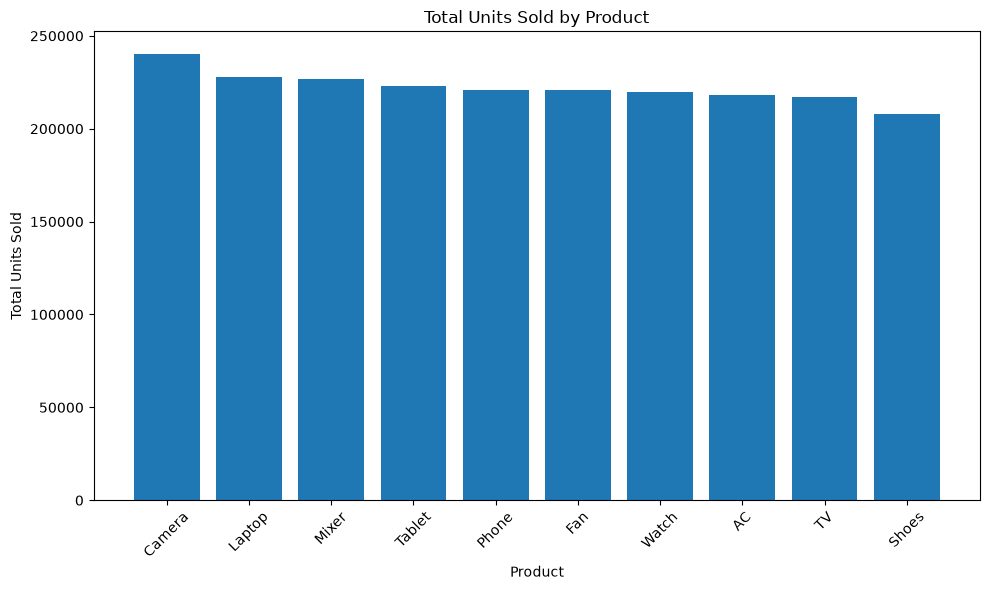

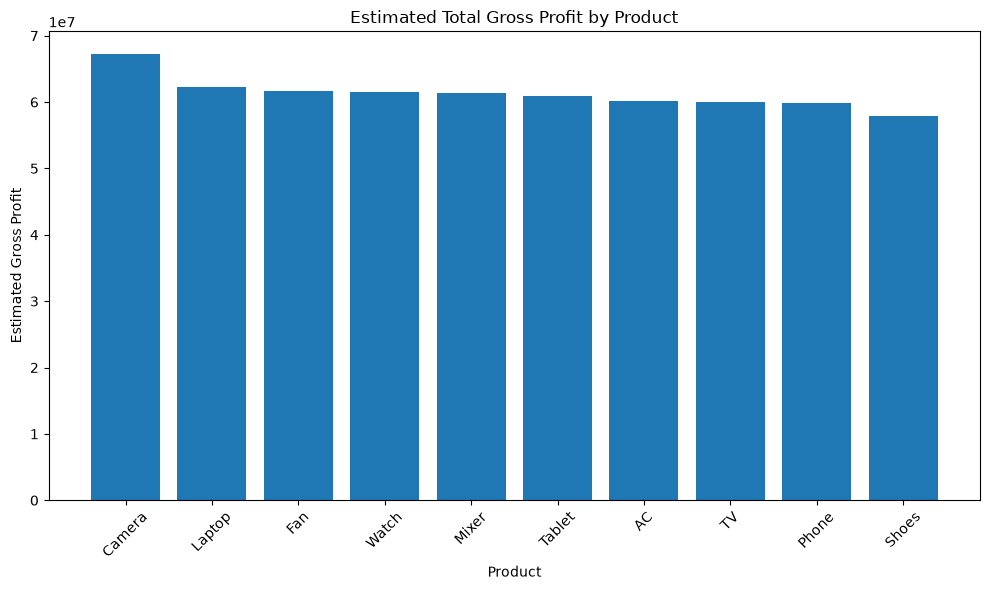

In [29]:

# Chart 1: Total Units Sold by Product
sales_chart = product_analysis.sort_values(
    "Total_Units_Sold", ascending=False
)

plt.figure(figsize=(10, 6))
plt.bar(
    sales_chart["Product_Name"],
    sales_chart["Total_Units_Sold"]
)
plt.title("Total Units Sold by Product")
plt.xlabel("Product")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Chart 2: Estimated Total Gross Profit by Product
profit_chart = product_analysis.sort_values(
    "Total_Gross_Profit", ascending=False
)

plt.figure(figsize=(10, 6))
plt.bar(
    profit_chart["Product_Name"],
    profit_chart["Total_Gross_Profit"]
)
plt.title("Estimated Total Gross Profit by Product")
plt.xlabel("Product")
plt.ylabel("Estimated Gross Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [30]:

# Analyze performance by supplier
supplier_analysis = (
    df_eda.groupby("Supplier_Name")
    .agg(
        Total_Units_Sold=("Units_Sold", "sum"),
        Total_Stock=("Stock_Quantity", "sum"),
        Average_Shipping_Days=("Shipping_Time_Days", "mean"),
        Average_Profit_Per_Unit=("Profit_Per_Unit", "mean"),
        Total_Gross_Profit=(
            "Profit_Per_Unit",
            lambda x: (
                x * df_eda.loc[x.index, "Units_Sold"]
            ).sum()
        )
    )
    .reset_index()
)

# Sort suppliers by estimated gross profit
supplier_analysis = supplier_analysis.sort_values(
    "Total_Gross_Profit",
    ascending=False
)

print("Supplier-wise Performance:")
display(supplier_analysis.round(2))


Supplier-wise Performance:


,Supplier_Name,Total_Units_Sold,Total_Stock,Average_Shipping_Days,Average_Profit_Per_Unit,Total_Gross_Profit
4,Supplier E,452768,750660,5.55,277.17,125550272
2,Supplier C,448597,762095,5.39,274.67,124050671
0,Supplier A,447389,761035,5.48,277.67,123069384
1,Supplier B,442191,749617,5.52,275.28,122865551
3,Supplier D,431563,740362,5.54,274.17,117388326


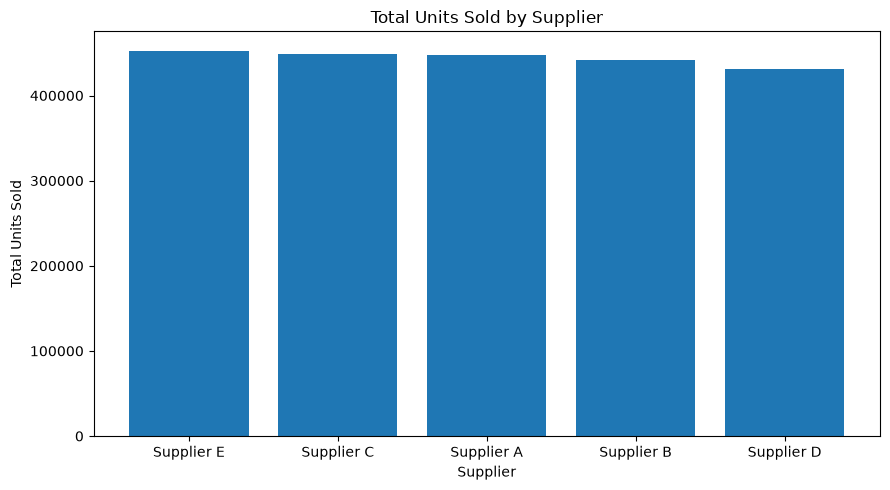

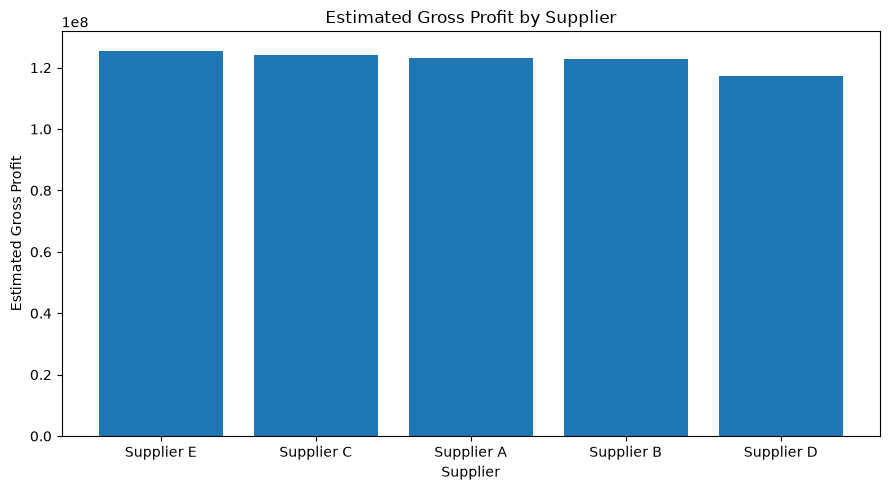

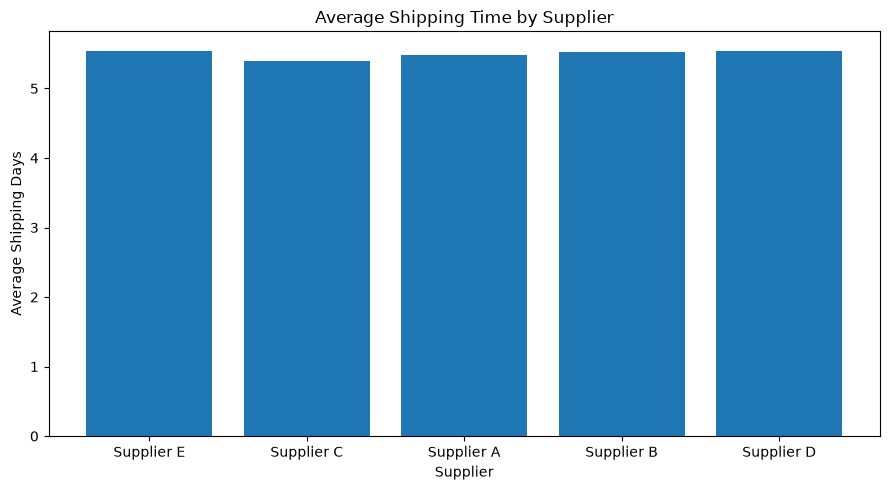

In [31]:

# Chart 1: Units sold by supplier
plt.figure(figsize=(9, 5))
plt.bar(
    supplier_analysis["Supplier_Name"],
    supplier_analysis["Total_Units_Sold"]
)
plt.title("Total Units Sold by Supplier")
plt.xlabel("Supplier")
plt.ylabel("Total Units Sold")
plt.tight_layout()
plt.show()


# Chart 2: Estimated gross profit by supplier
plt.figure(figsize=(9, 5))
plt.bar(
    supplier_analysis["Supplier_Name"],
    supplier_analysis["Total_Gross_Profit"]
)
plt.title("Estimated Gross Profit by Supplier")
plt.xlabel("Supplier")
plt.ylabel("Estimated Gross Profit")
plt.tight_layout()
plt.show()


# Chart 3: Average shipping time by supplier
plt.figure(figsize=(9, 5))
plt.bar(
    supplier_analysis["Supplier_Name"],
    supplier_analysis["Average_Shipping_Days"]
)
plt.title("Average Shipping Time by Supplier")
plt.xlabel("Supplier")
plt.ylabel("Average Shipping Days")
plt.tight_layout()
plt.show()


In [32]:

# Analyze inventory by warehouse
warehouse_analysis = (
    df_eda.groupby("Warehouse_Location")
    .agg(
        Total_Stock=("Stock_Quantity", "sum"),
        Total_Units_Sold=("Units_Sold", "sum"),
        Total_Records=("Product_ID", "count"),
        Average_Shipping_Days=("Shipping_Time_Days", "mean")
    )
    .reset_index()
)

# Count records at or below reorder level by warehouse
low_stock_by_warehouse = (
    df_eda.assign(
        Low_Stock=df_eda["Stock_Quantity"] <= df_eda["Reorder_Level"]
    )
    .groupby("Warehouse_Location")["Low_Stock"]
    .sum()
    .reset_index(name="Records_At_or_Below_Reorder")
)

warehouse_analysis = warehouse_analysis.merge(
    low_stock_by_warehouse,
    on="Warehouse_Location"
)

warehouse_analysis = warehouse_analysis.sort_values(
    "Total_Stock", ascending=False
)

print("Warehouse-wise Inventory Analysis:")
display(warehouse_analysis.round(2))


Warehouse-wise Inventory Analysis:


,Warehouse_Location,Total_Stock,Total_Units_Sold,Total_Records,Average_Shipping_Days,Records_At_or_Below_Reorder
0,Bangalore,761135,449298,3002,5.55,567
4,Mumbai,757200,451363,3024,5.53,615
3,Hyderabad,755963,447781,3032,5.44,607
1,Chennai,753070,438034,3010,5.53,629
2,Delhi,736401,436032,2932,5.43,597


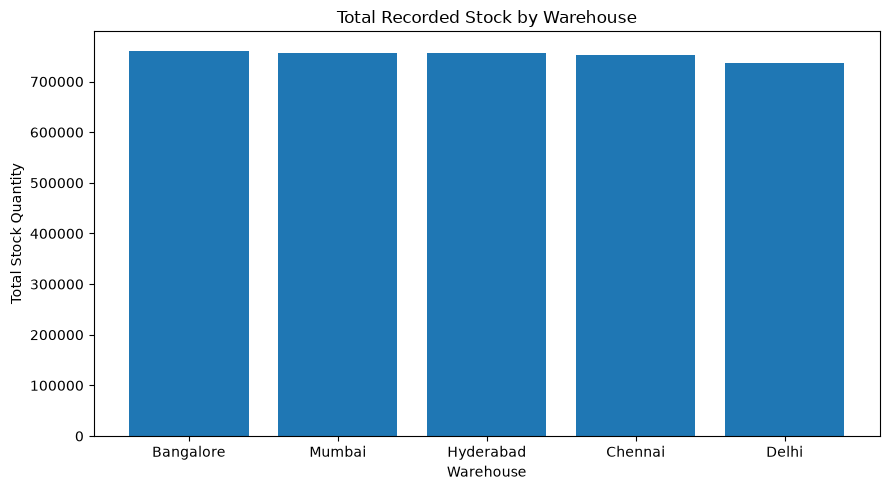

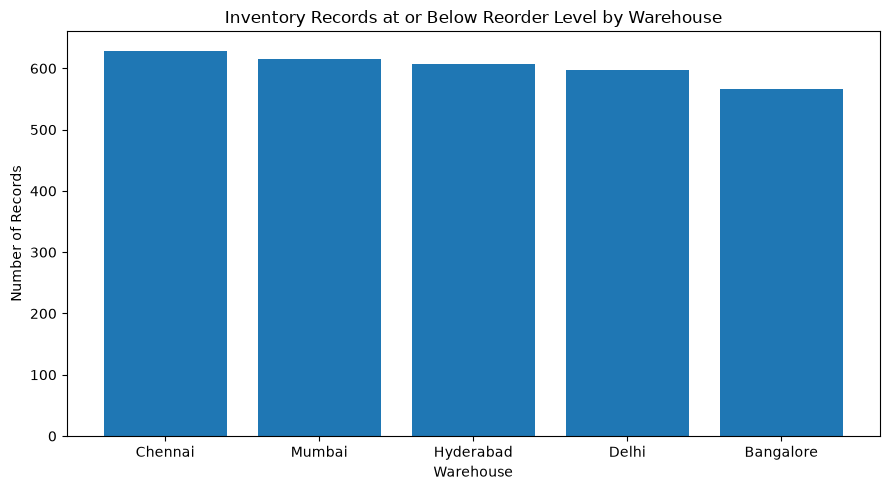

In [33]:

# Chart 1: Total stock by warehouse
plt.figure(figsize=(9, 5))
plt.bar(
    warehouse_analysis["Warehouse_Location"],
    warehouse_analysis["Total_Stock"]
)
plt.title("Total Recorded Stock by Warehouse")
plt.xlabel("Warehouse")
plt.ylabel("Total Stock Quantity")
plt.tight_layout()
plt.show()


# Chart 2: Records at or below reorder level
low_stock_chart = warehouse_analysis.sort_values(
    "Records_At_or_Below_Reorder",
    ascending=False
)

plt.figure(figsize=(9, 5))
plt.bar(
    low_stock_chart["Warehouse_Location"],
    low_stock_chart["Records_At_or_Below_Reorder"]
)
plt.title("Inventory Records at or Below Reorder Level by Warehouse")
plt.xlabel("Warehouse")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


In [34]:

# Overall shipping statistics
print("========== SHIPPING PERFORMANCE ==========")

print("Average shipping days:",
      round(df_eda["Shipping_Time_Days"].mean(), 2))

print("Median shipping days:",
      round(df_eda["Shipping_Time_Days"].median(), 2))

print("Minimum shipping days:",
      df_eda["Shipping_Time_Days"].min())

print("Maximum shipping days:",
      df_eda["Shipping_Time_Days"].max())

# Count records by shipping duration
shipping_distribution = (
    df_eda["Shipping_Time_Days"]
    .value_counts()
    .sort_index()
    .rename_axis("Shipping_Days")
    .reset_index(name="Record_Count")
)

print("\nShipping duration distribution:")
display(shipping_distribution)

# Calculate monthly average shipping time
df_eda["Order_Month"] = (
    df_eda["Order_Date"].dt.to_period("M").astype(str)
)

monthly_shipping = (
    df_eda.groupby("Order_Month")
    .agg(
        Average_Shipping_Days=("Shipping_Time_Days", "mean"),
        Total_Orders=("Product_ID", "count")
    )
    .reset_index()
)

print("\nFirst 12 months of shipping performance:")
display(monthly_shipping.head(12).round(2))


========== SHIPPING PERFORMANCE ==========
Average shipping days: 5.5
Median shipping days: 6.0
Minimum shipping days: 1
Maximum shipping days: 10

Shipping duration distribution:


,Shipping_Days,Record_Count
0,1,1519
1,2,1557
2,3,1469
3,4,1444
4,5,1505
5,6,1497
6,7,1507
7,8,1465
8,9,1520
9,10,1517



First 12 months of shipping performance:


,Order_Month,Average_Shipping_Days,Total_Orders
0,2023-01,5.60,653
1,2023-02,5.53,599
2,2023-03,5.33,647
3,2023-04,5.53,653
4,2023-05,5.64,653
5,2023-06,5.36,648
6,2023-07,5.37,655
7,2023-08,5.46,600
8,2023-09,5.52,602
9,2023-10,5.48,633


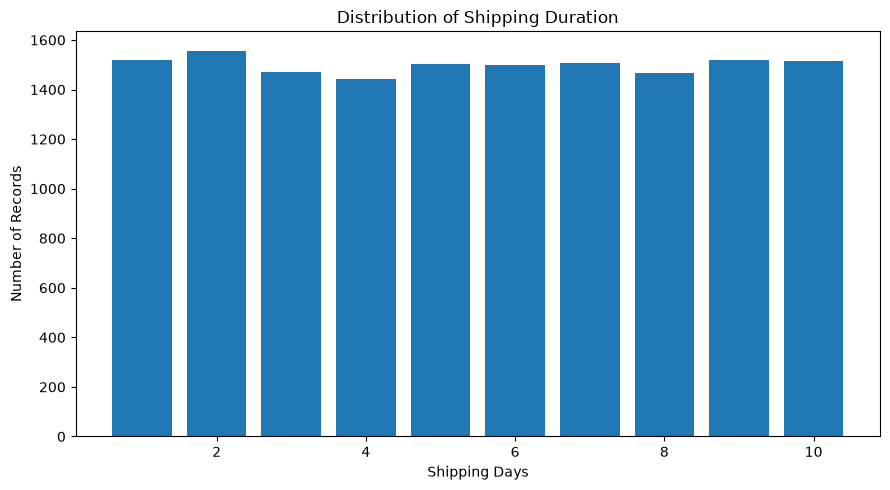

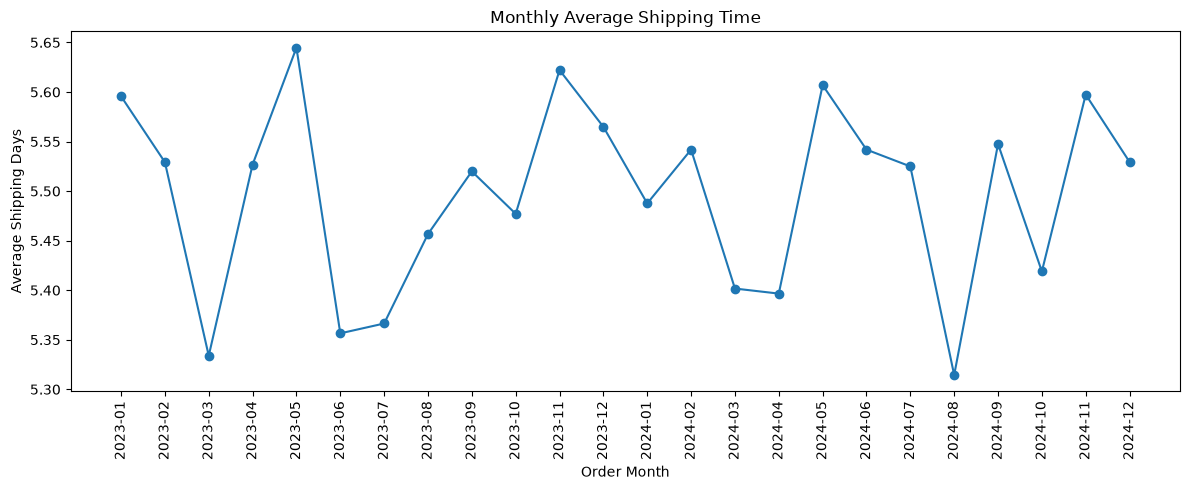

In [35]:

# Chart 1: Shipping duration distribution
plt.figure(figsize=(9, 5))
plt.bar(
    shipping_distribution["Shipping_Days"],
    shipping_distribution["Record_Count"]
)
plt.title("Distribution of Shipping Duration")
plt.xlabel("Shipping Days")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


# Chart 2: Monthly average shipping time
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_shipping["Order_Month"],
    monthly_shipping["Average_Shipping_Days"],
    marker="o"
)
plt.title("Monthly Average Shipping Time")
plt.xlabel("Order Month")
plt.ylabel("Average Shipping Days")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [36]:

# 1. Highest-selling product
top_selling_product = product_analysis.loc[
    product_analysis["Total_Units_Sold"].idxmax()
]

# 2. Highest gross-profit product
top_profit_product = product_analysis.loc[
    product_analysis["Total_Gross_Profit"].idxmax()
]

# 3. Warehouse with highest recorded stock
highest_stock_warehouse = warehouse_analysis.loc[
    warehouse_analysis["Total_Stock"].idxmax()
]

# 4. Warehouse with most low-stock records
most_low_stock_warehouse = warehouse_analysis.loc[
    warehouse_analysis["Records_At_or_Below_Reorder"].idxmax()
]

# 5. Supplier with highest estimated gross profit
top_profit_supplier = supplier_analysis.loc[
    supplier_analysis["Total_Gross_Profit"].idxmax()
]

# Display findings
print("========== BUSINESS FINDINGS ==========")

print(
    f"Top-selling product: {top_selling_product['Product_Name']} "
    f"({top_selling_product['Total_Units_Sold']:,.0f} units)"
)

print(
    f"Highest gross-profit product: "
    f"{top_profit_product['Product_Name']} "
    f"({top_profit_product['Total_Gross_Profit']:,.2f})"
)

print(
    f"Warehouse with highest recorded stock: "
    f"{highest_stock_warehouse['Warehouse_Location']} "
    f"({highest_stock_warehouse['Total_Stock']:,.0f} units)"
)

print(
    f"Warehouse with most low-stock records: "
    f"{most_low_stock_warehouse['Warehouse_Location']} "
    f"({most_low_stock_warehouse['Records_At_or_Below_Reorder']:,.0f} records)"
)

print(
    f"Supplier with highest estimated gross profit: "
    f"{top_profit_supplier['Supplier_Name']} "
    f"({top_profit_supplier['Total_Gross_Profit']:,.2f})"
)

print(
    f"Average shipping duration: "
    f"{df_eda['Shipping_Time_Days'].mean():.2f} days"
)

print(
    f"Total records at or below reorder level: "
    f"{(df_eda['Stock_Quantity'] <= df_eda['Reorder_Level']).sum():,}"
)


========== BUSINESS FINDINGS ==========
Top-selling product: Camera (240,401 units)
Highest gross-profit product: Camera (67,289,924.00)
Warehouse with highest recorded stock: Bangalore (761,135 units)
Warehouse with most low-stock records: Chennai (629 records)
Supplier with highest estimated gross profit: Supplier E (125,550,272.00)
Average shipping duration: 5.50 days
Total records at or below reorder level: 3,015
